# Preprocess and Epoch Thapar EEG Data

## Objective

Prepare clean, stimulus-locked EEG epochs from the Thapar recognition-memory dataset for ERP analysis and within-subject decoding.

## Analysis Scope

This notebook processes participant 3076. It converts the raw continuous EEG recording into artifact-screened epochs labeled `correct_old` and `correct_new`.

## Pipeline Overview

1. Load raw CNT data and verify recording structure.
2. Relabel ocular electrodes as EOG channels.
3. Parse test-presentation and response-marker pairs.
4. Select correctly recognized old and new trials.
5. Filter, downsample, repair bad channels, and re-reference EEG.
6. Identify and remove ocular ICA components after visual review.
7. Create baseline-corrected epochs from −200 to 1500 ms.
8. Inspect and reject high-amplitude artifact epochs.
9. Save cleaned epochs and the ICA solution for downstream ERP and decoding analyses.

## Define Architecture and Paths


In [143]:
#Upon opening this file, make sure kernel selected is thapar EEG

"""
TO MAKE A CHANGE PUT IN TERMINAL 
git add .
git commit -m "update markdowns"
git push
"""

"""

"""

from pathlib import Path
import mne

notebook_folder = Path.cwd()
project_folder = notebook_folder.parent
raw_data_folder = project_folder / "data" / "raw"

print("Notebook folder:", notebook_folder)
print("Project folder:", project_folder)
print("Raw-data folder:", raw_data_folder)
print("Raw-data folder exists:", raw_data_folder.exists())

print("Path Here: " ,Path.cwd())

notebook_folder = Path.cwd()
project_folder = notebook_folder.parent
raw_data_folder = project_folder / "data" / "raw"

files = sorted(raw_data_folder.iterdir())

print("Files Names in Raw Data:")
for file in files:
    print(file.name)




Notebook folder: /Users/reedsussman/Desktop/thapar_lab/notebooks
Project folder: /Users/reedsussman/Desktop/thapar_lab
Raw-data folder: /Users/reedsussman/Desktop/thapar_lab/data/raw
Raw-data folder exists: True
Path Here:  /Users/reedsussman/Desktop/thapar_lab/notebooks
Files Names in Raw Data:
3076.cnt
3087.cnt
3103.cnt
BMCmastoidref40.txt
seven_bin.txt


## Load 1 Participant (3076)

### Understand Data

- Sampling Rate     |   1000 Hz
- Channels          |   40 Recorded Channels (36 EEG and 4 EOG)
- Time points       |   3168.0 s (3,168,000 time points)

### Relabel EOG Channels (currently labeled as EEG)

- HEOL: Horizontal eye electrode left
- HEOR: Horizontal eye electrode right
- VEOU: Vertical eye electrode upper
- VEOL: Vertical eye electrode lower


In [144]:

from collections import Counter

subject_file = raw_data_folder / "3103.cnt" #create path pointing to participants recording

print("File exists:", subject_file.exists()) 
print("File path:", subject_file)


raw = mne.io.read_raw_cnt(
    subject_file,
    preload=False,
)

print(raw)

"""
From raw: 
40 recorded channels
3,168,000 time samples per channel
3168.0 seconds
1000 Hz is the sampling rate, so there is 1 ms between time samples
"""

"""
Now, let's verify those conclusions
"""
sampling_rate = raw.info["sfreq"]
number_of_channels = raw.info["nchan"]
number_of_samples = raw.n_times
duration_seconds = number_of_samples / sampling_rate

print("Sampling rate:", sampling_rate)
print("Number of channels:", number_of_channels)
print("Number of samples:", number_of_samples)
print("Duration in seconds:", duration_seconds)
print("Duration in minutes:", duration_seconds / 60)



channel_names = raw.ch_names
channel_types = raw.get_channel_types()

for index, (name, channel_type) in enumerate(
    zip(channel_names, channel_types)
):
    print(index, name, channel_type)


"""
HEOL: Horizontal eye electrode left
HEOR: Horizontal eye electrode right
VEOU: Vertical eye electrode upper
VEOL: Vertical eye electrode lower

currently those are being labeled as EEG despite being EOG, so change them
"""
eog_channels = [
    "HEOL",
    "HEOR",
    "VEOU",
    "VEOL",
]

#go into data and fix these types
raw.set_channel_types(
    {channel: "eog" for channel in eog_channels}
)


#count number of eeg and eog channels
channel_type_counts = Counter(
    raw.get_channel_types()
)

#we should get 36 EEG channels and 4 EOG Channels
#keep the EOG data rather than discard bc can be helpful in removing artifacts
print(channel_type_counts)




File exists: True
File path: /Users/reedsussman/Desktop/thapar_lab/data/raw/3103.cnt
<RawCNT | 3103.cnt, 40 x 2999000 (2999.0 s), ~50 KiB, data not loaded>
Sampling rate: 1000.0
Number of channels: 40
Number of samples: 2999000
Duration in seconds: 2999.0
Duration in minutes: 49.983333333333334
0 HEOL eeg
1 HEOR eeg
2 FP1 eeg
3 FP2 eeg
4 VEOU eeg
5 VEOL eeg
6 F7 eeg
7 F3 eeg
8 FZ eeg
9 F4 eeg
10 F8 eeg
11 FT7 eeg
12 FC3 eeg
13 FCZ eeg
14 FC4 eeg
15 FT8 eeg
16 T3 eeg
17 C3 eeg
18 CZ eeg
19 C4 eeg
20 T4 eeg
21 TP7 eeg
22 CP3 eeg
23 CPZ eeg
24 CP4 eeg
25 TP8 eeg
26 A1 eeg
27 T5 eeg
28 P3 eeg
29 PZ eeg
30 P4 eeg
31 T6 eeg
32 A2 eeg
33 O1 eeg
34 OZ eeg
35 O2 eeg
36 FT9 eeg
37 FT10 eeg
38 PO1 eeg
39 PO2 eeg
Counter({'eeg': 36, 'eog': 4})


/var/folders/74/gs9ybn1x28z998g5dr4ffs5w0000gn/T/ipykernel_50442/2232835682.py:9: RuntimeWarning:   Could not parse meas date from the header. Setting to None.
  raw = mne.io.read_raw_cnt(


## Understand the different annotations, their meanings, and how many events each has.

**Code 5:** Study-phase presentation of an item in the studied-once condition (75)

**Code 8:** Study-phase presentation of an item in the studied-once condition (75)

**Code 10:** Test presentation of an old item studied once (75)

**Code 15:** Test presentation of an old item studied twice (75)

**Code 18 or 20:** Test presentation of a new item (150)

These test-presentation codes take place exactly when the participant is presented with an item

**Code 30, 35, 40, or 45:** Participant responded old

**Code 55 or 60:** participant responded new

### IMPORTANT DISTINCTION:

The response codes in this code are after the participant makes their original
selection. An object is presented (and a code logs this), then the participant selects old or new
(no code logs this) then a bit after, they are asked why they made their decision (a code logs this)

What is therefore important about the response codes is not when they are, but whether or not the
participant made the correct decision. In terms of timing, we care 200 ms before and 1500 ms after
the test-presentation to look for ERP.

For example, a 10 followed by a 60 is the test-presentation of an old item studied once, followed by
the participant guessing that it was a new item -> a miss. We care about hits!


In [145]:
import numpy as np

print("Number of annotations:", len(raw.annotations))

print(raw.annotations)

event_codes, event_counts = np.unique(
    raw.annotations.description,
    return_counts=True,
)


#print each event code, as well as how many times it occurs
for code, count in zip(event_codes, event_counts):
    print(code, count)





print("Number of annotations:", len(raw.annotations))
print(raw.annotations)

# Get each event code and how many times it occurs
event_codes, event_counts = np.unique(
    raw.annotations.description,
    return_counts=True,
)

# Sort codes numerically rather than alphabetically
sorted_events = sorted(
    zip(event_codes, event_counts),
    key=lambda event: int(event[0]),
)

print("\nEvent codes, in numeric order:")
for code, count in sorted_events:
    print(f"Code {code}: {count}")

Number of annotations: 825
<Annotations | 825 segments: 10 (75), 15 (75), 18 (150), 25 (2), 40 (6), ...>
10 75
15 75
18 150
25 2
40 6
45 158
5 75
50 1
55 131
60 2
8 150
Number of annotations: 825
<Annotations | 825 segments: 10 (75), 15 (75), 18 (150), 25 (2), 40 (6), ...>

Event codes, in numeric order:
Code 5: 75
Code 8: 150
Code 10: 75
Code 15: 75
Code 18: 150
Code 25: 2
Code 40: 6
Code 45: 158
Code 50: 1
Code 55: 131
Code 60: 2


## Retrieve onset times of each event that we care about

What we expect to see is that every test-presentation code is followed by a response code.


In [146]:

#contains every event code in chronological order
descriptions = np.array(
    raw.annotations.description
)

#retrieves when every event happened (seconds from start of recording)
onsets = np.array(
    raw.annotations.onset
)


#possible item test-presentation code
test_item_codes = ["10", "15", "18", "20"]



#array same length as descriptions that becomes true at test-indecies and false othwerise
is_test_item = np.isin(
    descriptions,
    test_item_codes,
)

#get array of indecies where there are test presentation codes
test_indices = np.flatnonzero(
    is_test_item
)


first_test_index = test_indices[0]

#print 12 (arbitrary) next annotations following the first one to ensure it alternates (item, reponse, item, response)
for index in range(
    first_test_index,
    first_test_index + 12,
):
    #print 12 events (test followed by response is 2)
    print(
        index,
        descriptions[index],
        f"{onsets[index]:.3f} seconds",
    )

75 10 252.729 seconds
76 45 257.109 seconds
77 18 259.129 seconds
78 55 265.130 seconds
79 10 267.131 seconds
80 55 273.132 seconds
81 15 275.331 seconds
82 55 281.333 seconds
83 15 283.150 seconds
84 40 288.050 seconds
85 18 290.053 seconds
86 55 296.055 seconds


## Check the presentation-response pairs.

Create a list of unexpected pairs - tuples of two consecutive codes that don't followed the format : (test-presentation, response)

As is shown, none of those pairs exist (which is what we'd expect), indicating that for every test-presentation, the participant selected a response.


In [147]:
#look at first annotation (presentation)
item_index = test_indices[0]
#look at next annotation (response)
response_index = item_index + 1

#figure out code for first test item and its response
item_code = descriptions[item_index]
response_code = descriptions[response_index]


#get onset times of each
item_onset = onsets[item_index]
response_onset = onsets[response_index]

#figure out time between response and test
print("Item code:", item_code)
print("Response code:", response_code)
print("Item onset:", item_onset)
print("Response-marker onset:", response_onset)
print(
    "Time between markers:",
    response_onset - item_onset,
)



#Now check all pairs to make sure they are as expected
unexpected_pairs = []

response_codes = {
    "30", "35", "40", "45",
    "50",
    "55", "60",
}

#Check that for every test item, the next index (which holds the corresponding reponse)
#contains a valid response code, otherwise append it to unexpected pairs and let the user know
for item_index in test_indices:
    response_index = item_index + 1
    response_code = descriptions[response_index]

    if response_code not in response_codes:
        unexpected_pairs.append(
            (
                item_index,
                descriptions[item_index],
                response_code,
            )
        )

print("Number of test items:", len(test_indices))
print("Unexpected pairs:", unexpected_pairs)

Item code: 10
Response code: 45
Item onset: 252.729
Response-marker onset: 257.109
Time between markers: 4.379999999999967
Number of test items: 300
Unexpected pairs: [(np.int64(530), '18', '25'), (np.int64(629), '18', '25')]


## Filter the data to only consider the following cases:

- old test-presentation followed by old response (Correct New)

**AND**

- new test-presentation followed by new response (Correct Old)

By comparing correctly identified old and new items, we can hopefully train a model to classify an item based on whether the participant is aware that they've seen it before or aware that they haven't.

For these events:

1. Convert onset times in seconds -> sample numbers (since the start)
2. Convert class labels -> numerical labels
    - "correct_old": 1
    - "correct_new": 2


In [148]:
old_response_codes = {
    "30",
    "35",
    "40",
    "45",
}

new_response_codes = {
    "55",
    "60",
}

#classify trials (pair of test-presentation and response)
def classify_trial(item_code, response_code):
    if (
        item_code == "10"
        and response_code in old_response_codes
    ):
        return "hit_once"
    if (
        item_code == "15"
        and response_code in old_response_codes
    ):
        return "hit_twice"
    if (
        item_code in {"18", "20"}
        and response_code in new_response_codes
    ):
        return "correct_rejection"
    
    #classify old as new
    if (
        item_code in {"10", "15"}
        and response_code in new_response_codes
    ):
        return "miss"

    #classify new as old
    if (
        item_code in {"18", "20"}
        and response_code in old_response_codes
    ):
        return "false_alarm"

    #in case something falls through cracks
    return "unclassified"

#testing purposes

#print(classify_trial("10", "30"))
#print(classify_trial("15", "60"))
#print(classify_trial("18", "35"))
#print(classify_trial("18", "50"))




#for the binary case, we only case about correct_old and correct_new
model_label_map = {
    "hit_once": "correct_old",
    "hit_twice": "correct_old",
    "correct_rejection": "correct_new",
}

selected_item_indices = []
trial_labels = []
excluded_pairs = []

for item_index in test_indices:

    item_code = descriptions[item_index]
    response_code = descriptions[item_index + 1]

    trial_type = classify_trial(
        item_code,
        response_code,
    )

    # Skip misses, false alarms, and unclassified trials
    if trial_type not in model_label_map:
        excluded_pairs.append((item_code, response_code))
        continue

    model_label = model_label_map[trial_type]

    selected_item_indices.append(item_index)
    trial_labels.append(model_label)


print(len(trial_labels))
print(Counter(trial_labels))
print("Excluded pair counts:", Counter(excluded_pairs))

# Convert selected annotation positions into onset times
selected_onsets = onsets[selected_item_indices]

# Convert onset times (seconds) into EEG sample numbers
selected_samples = raw.time_as_index(
    selected_onsets,
    use_rounding=True,
)

print(selected_samples)

# Numerical labels for the model
event_id = {
    "correct_old": 1,
    "correct_new": 2,
}

numeric_labels = np.array([
    event_id[label]
    for label in trial_labels
])

print(numeric_labels)

259
Counter({'correct_old': 138, 'correct_new': 121})
Excluded pair counts: Counter({('18', '45'): 23, ('10', '55'): 9, ('15', '55'): 3, ('18', '40'): 3, ('18', '25'): 2, ('18', '50'): 1})
[ 252729  259129  283150  290053  298055  306256  314259  322077  327646
  335864  343866  349085  357104  365321  373322  381157  389176  397378
  405197  413200  418784  424085  432104  437639  445442  453660  461462
  474931  488866  496884  502603  507922  513405  518874  526876  532199
  537519  542804  548272  553623  561642  569842  574865  593481  601517
  609536  617538  625556  636698  642016  647334  652651  658034  663354
  668738  674139  679522  687725  695528  703547  711749  718483  723769
  731771  738306  743690  751892  759695  767713  773198  778298  783866
  791674  797009  802310  807828  813213  818532  823683  839720  847922
  855742  866344  872260  880260  886245  891663  899669  905255  910406
  918425 1181216 1189236 1197238 1205240 1210625 1215776 1229063 1237081
 1242337

## Convert selected trials (presentation, response) pairs into events for MNE

Each event represents one selected trials

    [sample number (where test-code starts), 0, class_label]

np.column_stack comobines the 3 separate 1D arrays into a 3 column event table


In [149]:
events = np.column_stack([
    #column stack combines 3 separate 1D arrays into 3 column event table
    selected_samples,
    np.zeros(len(selected_samples), dtype=int),
    numeric_labels,
])

#each event now represents one selected trial [sample number, previous value, class label]
#the previous value is a placeholder required by MNE

print("Events shape:", events.shape)
print("First five events:")
print(events[:5])

Events shape: (259, 3)
First five events:
[[252729      0      1]
 [259129      0      2]
 [283150      0      1]
 [290053      0      2]
 [298055      0      2]]


## Load a copy of the data into RAM and drop the flat channels.

FT9 and FT10 electrodes were placed over the ears without gel


In [150]:
#create a copy of the data so that we do not override it
raw_preprocessed = raw.copy()

#load the data (the actual voltage samples into RAM (as originally preload was false))
raw_preprocessed.load_data()

# These electrodes were placed over the ears without gel
raw_preprocessed.drop_channels([
    "FT9",
    "FT10",
])


print("Original data loaded:", raw.preload)
print("Working copy loaded:", raw_preprocessed.preload)

Reading 0 ... 2998999  =      0.000 ...  2998.999 secs...
Original data loaded: False
Working copy loaded: True


## Bandpass filter the EEG and EOG signals

### Keep activity between 0.5 and 40 Hz

- frequencies below 0.5 Hz contain very slow drift
- frequencies above 40 Hz have a lot of muscle and electrical noise

FN400 (ERP) and LPC (Late Positive Component, which comes from recognition,  are relatively slow voltage changes)


In [151]:

#set to select both eeg and eog (all 40 channels)
signal_picks = mne.pick_types(
    raw_preprocessed.info,
    eeg=True,
    eog=True,
)

#keep activity between .1 and 40 Hz bc frequencies below .1 Hz are usually very slow drift
#and frequencies above 40 Hz have a lot of muscle and electrical noise
#also surpresses the 60Hz electrical noise common in US

#FN400 and LPC are relatively slow voltage changes
#apply the filter only to the channels listed in signal_picks (which in this case is all of the channels)
raw_preprocessed.filter(
    l_freq=0.5,
    h_freq=40.0,
    picks=signal_picks,
)

print(raw_preprocessed)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 6601 samples (6.601 s)

<RawCNT | 3103.cnt, 38 x 2999000 (2999.0 s), ~869.5 MiB, data loaded>


## Downsample the Data from 1000 Hz to 250 Hz.

Pass in the events so that the sample number is updated to fit the new sampling rate.

The purpose of this is to reduce input size into the model.



In [152]:
raw_preprocessed, events_resampled = (
    raw_preprocessed.resample(
        sfreq=250,#choose frequency of 250 Hz for sampling rate
        events=events, #pass in events so that they are updated (sample number must be updated to fit new sampling rate)
    )
)

print("New sampling rate:", raw_preprocessed.info["sfreq"])
print("New number of samples:", raw_preprocessed.n_times)
print("First five original events:")
print(events[:5])
print("First five resampled events:")
print(events_resampled[:5])

New sampling rate: 250.0
New number of samples: 749750
First five original events:
[[252729      0      1]
 [259129      0      2]
 [283150      0      1]
 [290053      0      2]
 [298055      0      2]]
First five resampled events:
[[63182     0     1]
 [64782     0     2]
 [70788     0     1]
 [72513     0     2]
 [74514     0     2]]


## Channel Analysis: (Find any bad EEG channels):

- Look at standard deviations of each channel, as well as V(t) plot for first 20 seconds
    - If standard deviation is 0 and V(t) is flat, the channel is not recording useful data
    - If the standard deviation is significantly large, and V(t) is all over the place, the channel is likely corrupted.


In [153]:
# Select only the 36 scalp-EEG channels
eeg_picks = mne.pick_types(
    raw_preprocessed.info,
    eeg=True,
    eog=False,
)

# Calculate each channel's standard deviation
# MNE stores voltage in volts, so multiply by 1e6 for microvolts
eeg_standard_deviations = (
    raw_preprocessed
    .get_data(picks=eeg_picks)
    .std(axis=1)
    * 1e6
)

# Pair each channel name with its standard deviation
channel_variability = list(zip(
    np.array(raw_preprocessed.ch_names)[eeg_picks],
    eeg_standard_deviations,
))

# Print from most variable to least variable
for channel, standard_deviation in sorted(
    channel_variability,
    key=lambda pair: pair[1],
    reverse=True,
):
    print(
        channel,
        f"{standard_deviation:.2f} µV",
    )

"""
we are looking for extremely small std (which could indicate flat or disconnected channel)
or extremely large std (which indicates a noisy electrode)
"""


inspection_channels = [
    "PO2",
    "FP1",
    "F3",
    "F4",
    "A2",
    "C3",
    "CZ",
    "PZ",
    "HEOL",
    "VEOU",
]

raw_preprocessed.plot(
    picks=inspection_channels,
    start=240,
    duration=20,
    scalings={
        "eeg": 200e-6,
        "eog": 500e-6,
    },
)

"""
What to notice from plot:
A2, FT9, FT10 are perfectly horizontal with no changing signal (might be reference)
PO2 is corrupted, makes sense why its std was 4300 uV

ASK THAPAR ABOUT A2 FT9 AND FT10
"""

#mark the bad channel
raw_preprocessed.info["bads"] = ["PO2"]


print(raw_preprocessed.info["bads"])

A1 74.05 µV
FP1 55.96 µV
FP2 54.32 µV
F7 28.22 µV
F3 21.98 µV
F8 19.31 µV
FZ 19.20 µV
FCZ 18.85 µV
FT7 17.31 µV
F4 17.26 µV
CZ 17.22 µV
CPZ 16.84 µV
FC3 16.29 µV
C3 15.94 µV
T5 14.78 µV
T3 14.75 µV
FC4 14.42 µV
TP7 14.40 µV
CP3 13.91 µV
C4 13.68 µV
P3 13.56 µV
T4 13.16 µV
CP4 13.08 µV
PZ 13.04 µV
FT8 12.88 µV
PO1 12.78 µV
P4 12.43 µV
TP8 12.31 µV
PO2 12.31 µV
O1 12.28 µV
O2 12.13 µV
OZ 12.07 µV
T6 11.34 µV
A2 0.00 µV
['PO2']


Channels marked as bad:
none


## Channel Interpolation:

One of the electrodes is compromised, so rather than passing on this lousy data into the model, we will replace it's valued with new ones. These new voltage values are interpolated at every time point based on a linear combination of nearby functioning electrodes.


In [154]:
#This loads standard coordinates for electrodes like F3, Cz, P02 (give MNE the physical scalp locations of the electrodes)
montage = mne.channels.make_standard_montage(
    "standard_1020"
)


raw_preprocessed.set_montage(
    montage, 
    match_case=False, #treat names like Cz and CZ as same electrode
    on_missing="warn", #if missing a position for a channel, warn us not crashing
)

print(raw_preprocessed.get_montage())

#the goal is that we are now missing PO2, but we can interpolate / estimate what its signal should've looked like using the nearby functioning electrodes


# Tell MNE which channel is currently bad
interpolated_channels = ["PO2"]
raw_preprocessed.info["bads"] = interpolated_channels

# Replace PO2 using the surrounding good electrodes
raw_preprocessed.interpolate_bads(
    reset_bads=True,
)

print(
    "Channels still marked bad:",
    raw_preprocessed.info["bads"],
)

po2_standard_deviation = (
    raw_preprocessed
    .get_data(picks=["PO2"])
    .std()
    * 1e6
)

print(
    "Interpolated PO2 standard deviation:",
    f"{po2_standard_deviation:.2f} µV",
)

<DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 34 channels>
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 94.2 mm
Computing interpolation matrix from 33 sensor positions
Interpolating 1 sensors
Channels still marked bad: []
Interpolated PO2 standard deviation: 11.64 µV


/var/folders/74/gs9ybn1x28z998g5dr4ffs5w0000gn/T/ipykernel_50442/2884049818.py:2: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage(


## Investigate other channels with high standard deviations

Next, for the channels with high standard deviations, we want to analyze and try to figure out why they are so variable.

- Look at their maximum voltage
- Look at what percent of their data is above 200 uV (if it is low, then we expect artifacts are the cause)

The results suggest that FP1, F3, and F4 exceeds 200 uV for only just ~1-2% of the recording
but occasionaly have ginormous artifacts.

For now, preserve them and later reject trials with massive spikes


In [155]:
channels_to_compare = [
    "FP1",
    "F3",
    "F4",
    "C3",
    "CZ",
    "PZ",
]

for channel in channels_to_compare:

    signal_microvolts = (
        raw_preprocessed
        .get_data(picks=[channel])[0]
        * 1e6
    )

    standard_deviation = signal_microvolts.std()

    percentile_99 = np.percentile(
        np.abs(signal_microvolts),
        99,
    )

    maximum_amplitude = np.max(
        np.abs(signal_microvolts)
    )

    percent_above_200 = (
        np.mean(np.abs(signal_microvolts) > 200)
        * 100
    )

    print(
        channel,
        f"SD={standard_deviation:.1f} µV,",
        f"99th percentile={percentile_99:.1f} µV,",
        f"maximum={maximum_amplitude:.1f} µV,",
        f"above 200 µV={percent_above_200:.2f}%",
    )




FP1 SD=56.0 µV, 99th percentile=204.4 µV, maximum=1412.2 µV, above 200 µV=1.07%
F3 SD=22.0 µV, 99th percentile=75.3 µV, maximum=212.2 µV, above 200 µV=0.00%
F4 SD=17.3 µV, 99th percentile=60.5 µV, maximum=155.3 µV, above 200 µV=0.00%
C3 SD=15.9 µV, 99th percentile=50.7 µV, maximum=189.0 µV, above 200 µV=0.00%
CZ SD=17.2 µV, 99th percentile=58.0 µV, maximum=690.3 µV, above 200 µV=0.00%
PZ SD=13.0 µV, 99th percentile=42.0 µV, maximum=573.5 µV, above 200 µV=0.00%


## Establish new reference (average of two mastoids)

### Why?

EEG doesn't measure an electrodes absolute voltage, but the voltage relative to a reference.

Average referencing replaces the original reference with the average of all usable scalp EEG channels, but we are not using average referencing here. Rather, we are re-referencing all EEG channels to the average of the two mastoids.

### Why?

We have more confidence that the students properly attached the two mastoids compared to the other channels.

### Why do we do this though if there already was reference? Ask prof thapar


In [156]:

#EEG doesn't measure an electrode's absolute voltage, but the voltage relative to a reference
#average referencing replaces the original reference with the average of all usable scalp EEG channels
# Re-reference all EEG channels to the average of the two mastoids
"""
This average is used rather than the average of all channels bc there is more confidence that the 
students properly attached the two mastoids compared to the other channels.

"""

raw_preprocessed.set_eeg_reference(
    ref_channels=["A1", "A2"],
    projection=False,
)


print(
    "Excluded flat channels:",
    raw_preprocessed.info["bads"],
)

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Excluded flat channels: []


## Where we are as of Now:

- Loaded one participant (3076) and verified the structure (40 channels, 1000Hz, 52.8 min of data)
- Relabeled 4 EEG channels -> EOG (as they track eye movements)
- Verified that each test is followed by a response
- Classified trials based on code, and isolated trials correctly recognized
- downsampled (1000 -> 250 Hz)
- identified abnormal channel (P02) and interpolated new data
- Recognized FP1, F3, F4 have extreme ocular artificats
- Applied rereferencing wrt mastoid average


## Ocular Artifact Detection Using ICA

A copy of the data is created to avoid messing with original data

### What is Independent Component Analysis (ICA)?

- ICA looks to explain the sources of variation in the data
- Each electrode contains a mixture of sources. For example,

    FP1(t) = a1 brain(t) + a2 blink (t) + a3 noise(t)

ICA assumes the channel data can be written as **X = AS**

- **X:** recorded electrode data (channels x time points)
- **A:** how strongly each component appears in each electrode (components x channels)
- **S:** the underlying components (components x time points)

ICA then estimates an "unmixing" operation

**S = W X**

- **S:** ICA's estimated underlying components
- **W:** The unmixing matrix learned by ICA
- **X:** The EEG signals recorded at the electrode

ICA does not know that something is a blink. It just separates signals that behave independently, and you can identify their meaning afterward

Each ICA component has a time course, a scalp distribution, and a frequency spectrum (a component is not an electrode)

We've set ICA to ignore grossly corrupted sections exceeding 1000 uV PTP

n_components = 0.99 sets the model to reduce dimensionality of the data using Principle Component Analysis (PCA), but keep enough PCA dimensions to explain 99% of the variance in the channel signals over time


In [157]:
# Use scalp EEG for ICA, excluding the mastoid reference electrodes
#Zip pairs each channel with its name, then the if statement only keeps them if scalp EEG
scalp_eeg_channels = [
    channel
    for channel, channel_type in zip(
        raw_preprocessed.ch_names,
        raw_preprocessed.get_channel_types(),
    )
    if (
        channel_type == "eeg"
        and channel not in {"A1", "A2"}
    )
]

#verify that we have 32 scalp eeg channels (40 - 2 mastoids - 4 EOG - FT9 - FT10 = 32)
print(
    "Number of scalp EEG channels:",
    len(scalp_eeg_channels),
)

# Create a temporary copy used only to fit ICA, wont alter the main EEG data
ica_fitting_data = raw_preprocessed.copy()

#find numerical positions of all eeg and eog channels (the ones that will receive additional filter)
ica_filter_picks = mne.pick_types(
    ica_fitting_data.info,
    eeg=True,
    eog=True,
)

# ICA performs better without slow drift
ica_fitting_data.filter(
    l_freq=1.0,
    h_freq=None, #existing 40 Hz cutoff remains in effect
    picks=ica_filter_picks,
)



"""
Each electrode contains a mixture of brain activity, blinks, eye movements, and noise

ICA tries to reverse these mixtures into components
    - a component here isn't an electrode, but a pattern distributed across multiple electrodes


"""
#create the ICA model
ica = mne.preprocessing.ICA(
    n_components=0.99, # reduce dimensionality but keep enough components to explain 99% of variance
    #then perform ICA in the reduced space
    random_state=97, #ensure rerunning notebook -> same result
    max_iter="auto", #ICA learns iteratively -> let MNE chose max iterations
)

#learn components from the 32 scalp EEG-channels
ica.fit(
    ica_fitting_data,
    picks=scalp_eeg_channels,

    # Ignore extremely corrupted data sections while fitting ICA (Peak to Peak range above 1000 uV)
    # Why? We don't want the huge spikes to control the ICA solution
    reject={
        "eeg": 1000e-6,
    },

    reject_by_annotation=True, #if any time ranges are annotated as bad
)

print(ica)

Number of scalp EEG channels: 32
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 825 samples (3.300 s)

Use rng= instead of random_state= in new code
Fitting ICA to data using 32 channels (please be patient, this may take a while)
    Rejecting  epoch based on EEG : ['FP2']
Artifact detected in [348500, 349000]
    Rejecting  epoch based on EEG : ['FP1', 'FP2']
Artifact detected in [383000, 383500]
    Rejecting  epoch based on EEG : ['FP2']
Artifact detected in [456500, 457000]
    Rejecting  epoch based on EEG : ['FZ', 'FCZ', 'PO1']
Artifact detected in [467500, 468000]
    Rejecting  epoch based on EEG : ['FP1']


## Ocular Artifact Candidate Identification

For each EOG Channel, MNE will:

1. take the time course of every ICA component
2. compare it with that of the EOG channel
3. calculate a relationship score
4. uses an automatic threshold to identify candidates

In other words, if an ICA component changes when EOG changes, the component may represent eye activity


In [158]:
import pandas as pd

candidate_eog_components = set() #empty set

#examine each eye electrode
for eog_channel in eog_channels:

    #compare each ICA components time with the selected EOG channel
    """
    For example, if some component repeatedly rises whenever VEOU records a blink,
    it will receive a strong EOG score and be returned as a candidate
    """
    #components that passed MNE's automatic threshold relationship score
    component_indices, scores = ica.find_bads_eog(
        ica_fitting_data,
        ch_name=eog_channel,
    )

    print(
        eog_channel,
        "candidate components:",
        component_indices,
    )

    #add the detectd component numbers to the set without creating duplicates 
    #a component detected using both veou and veol is only stored once
    candidate_eog_components.update(
        component_indices
    )


candidate_eog_components = sorted(
    candidate_eog_components
)

print(
    "All candidate eye components:",
    candidate_eog_components,
)


Using EOG channel: HEOL
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 2500 samples (10.000 s)

... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
-

## Temporal Comparison of ICA (EEG) Components to EOG Channels

The reason for this is that if a component is heavily correlated with EOG channels over time, then it is a stronger candidate to be eye-related artifact that we can remove.


In [159]:

#plot each candidates spatial pattern across the scalp
"""
Vertical blink component: should be strongest near the front of the head (FP1 and FP2)

"""
if candidate_eog_components:
    ica.plot_components(
        picks=candidate_eog_components
    )


"""
At this point, ICA has :
    1. learned the components
    2. identified possible eye components
    3. displayed them for inspection
"""

#verify that the EOG channels contain useful signals (look at SD and Maximum)
for eog_channel in eog_channels:

    #extract one EOG channel and convert volts into microvolts, calculate STD and Max to make sure
    #its not falt, has measurable activity, has plausible eye related voltage changes (quality control step)
    eog_signal = (
        raw_preprocessed
        .get_data(picks=[eog_channel])[0]
        * 1e6
    )

    print(
        eog_channel,
        f"SD={eog_signal.std():.1f} µV,",
        f"maximum={np.max(np.abs(eog_signal)):.1f} µV",
    )



#Rank the Most eye-correlated components
eog_scores = {}
top_eog_components = set()

for eog_channel in eog_channels:

    _, scores = ica.find_bads_eog(
        ica_fitting_data,
        ch_name=eog_channel,
    )

    eog_scores[eog_channel] = scores

    # Find the three components with the strongest absolute scores
    ranked_components = np.argsort(
        np.abs(scores) #magnitude
    )[::-1]

    top_three = ranked_components[:3]

    #select top 3 components
    print(
        eog_channel,
        [
            (
                int(component),
                round(float(scores[component]), 3),
            )
            for component in top_three
        ],
    )

    # Save the strongest two for visual inspection
    top_eog_components.update(
        top_three[:2]
    )

top_eog_components = sorted(
    top_eog_components
)

print(
    "Components to inspect:",
    top_eog_components,
)

top_eog_components = [
    int(component)
    for component in top_eog_components
]


eog_score_table = pd.DataFrame(
    {
        eog_channel: [
            eog_scores[eog_channel][component]
            for component in top_eog_components
        ]
        for eog_channel in eog_channels
    },
    index=[
        f"ICA{component:03d}"
        for component in top_eog_components
    ],
)

eog_score_table.index.name = "Component"

display(
    eog_score_table.round(3)
)

HEOL SD=41.8 µV, maximum=445.7 µV
HEOR SD=34.7 µV, maximum=383.6 µV
VEOU SD=10.1 µV, maximum=447.6 µV
VEOL SD=33.4 µV, maximum=339.8 µV
Using EOG channel: HEOL


... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 2500 samples (10.000 s)

... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 2500 sam

,HEOL,HEOR,VEOU,VEOL
Component,,,,
ICA000,-0.340,-0.207,0.121,0.791
ICA001,0.856,-0.802,0.688,0.312
ICA006,-0.021,-0.007,-0.246,-0.030


## Spatial Analysis of ICA Components


Now, we can see which ICA components are linked closest to EOG channels, giving us a rough indicator of which are most likely the artifact components that we want to remove.

That being said, the temporal match with eye activity is only one half of the problem. Before being confident that an ICA component is worth removing as ocular artifact, we must confirm that it spatially matches what we'd expect from ocular artifacts (near front of head for vertical eye movement or on opposing side for horizontal eye movement). For this, we plot each component and it's significance across electrodes.


Saving ICA figures to: /Users/reedsussman/Desktop/thapar_lab/results/figures/ica/3103


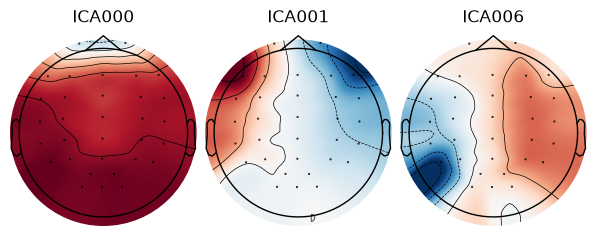

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
1499 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
1499 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
1499 matching events found
No baseline correction applied
0 projection items activated


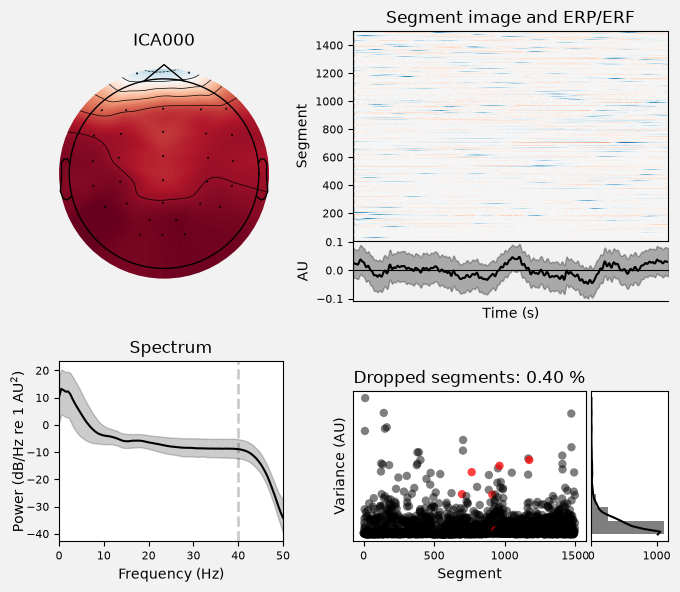

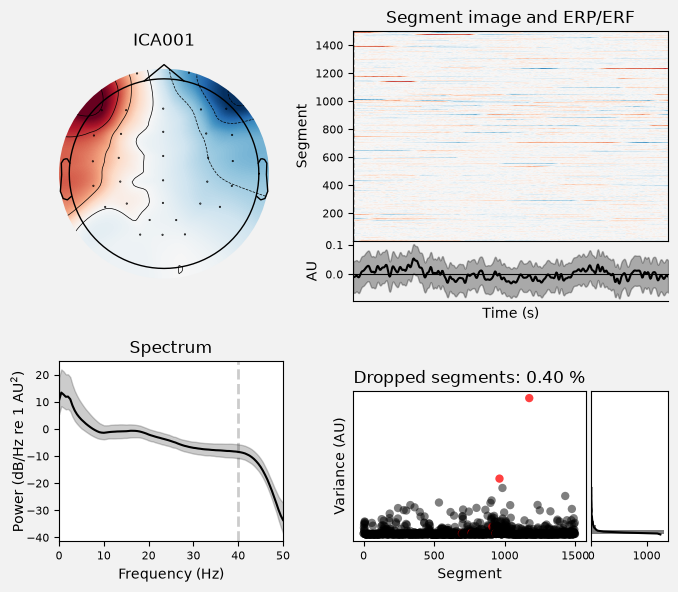

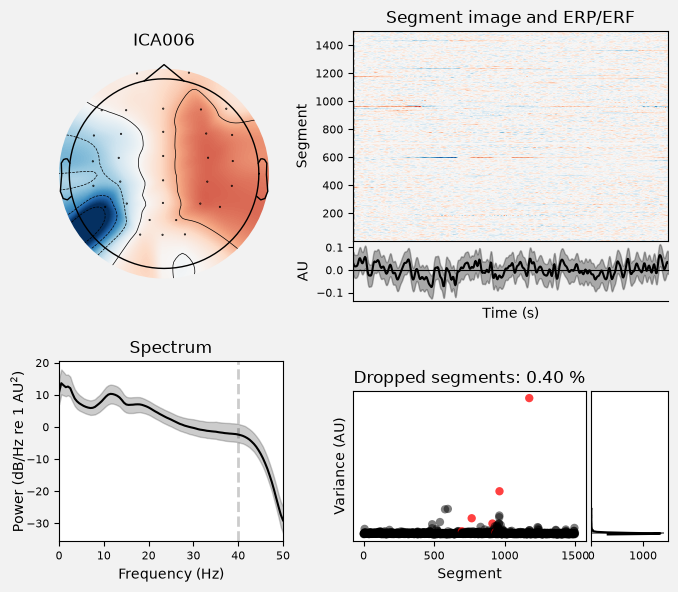

'\nWhen should you remove a component?\n    - strong relationship with EOG\n    - eye-like scalp distribution\n    - eye-like time course\n    - plausible frequency content\n'

In [160]:

#plot them to visually see
"""
Vertical blink should be strongest near fp1 and fp2

horizontal eye movement should yield opposing left/right frontal activity


"""

# Create a folder for this participant's ICA figures
participant_id = subject_file.stem

ica_figures_folder = (
    project_folder
    / "results"
    / "figures"
    / "ica"
    / participant_id
)

ica_figures_folder.mkdir(
    parents=True,
    exist_ok=True,
)

print("Saving ICA figures to:", ica_figures_folder)
# Plot and save the scalp topographies
component_figures = ica.plot_components(
    picks=top_eog_components,
    show=True,
)

# MNE may return one figure or a list of figures
if not isinstance(component_figures, list):
    component_figures = [component_figures]

for figure_number, figure in enumerate(
    component_figures,
    start=1,
):
    figure.savefig(
        ica_figures_folder
        / f"candidate_topographies_{figure_number}.png",
        dpi=300,
        bbox_inches="tight",
    )

property_figures = ica.plot_properties(
    ica_fitting_data,
    picks=top_eog_components,
    show=True,
)

for component, figure in zip(
    top_eog_components,
    property_figures,
):
    figure.savefig(
        ica_figures_folder
        / f"ica_component_{component:02d}_properties.png",
        dpi=300,
        bbox_inches="tight",
    )
"""
When should you remove a component?
    - strong relationship with EOG
    - eye-like scalp distribution
    - eye-like time course
    - plausible frequency content
"""


#print component-by-EOG score table

## Conclusions

**ICA000: strong ocular component**

**ICA005: strong ocular component**

For those two channels we have both:

1. **temporal evidence:**
    - components 0 and 5 had very strong correlations with HEOL, VEOU, and VEOl.
    - Their activity fluctuated over time similarly to those EOG channels
2. **Spatial evidence:**
    - The scalp maps show strong frontal activity near the eyes, especially around FP1 and FP2

Neither piece is sufficient alone, but together they make a a strong case.

ICA013 and ICA014: not strong related to EOG, leave them alone

Now, preview the correction


## Preview the Correction


Now that we've identified the ICA components that we suspect have strong ocular components, we want to make sure that removing them does not destroy the underlying EEG.

So, we'll plot EEG before removing the suspected ocular components and EEG after removing them, and make sure that the signals generally follow each other (underlying EEG shape preserved after removal)

**reasonable correction should:**

1. reduce large, slow frontal deflections associated with eye activity
2. preserve timing and general shape or ordinary EEG fluctuations
3. avoid flattening or substantially distorting the signal

this does not modify raw_preprocessed


Applying ICA to Raw instance
    Transforming to ICA space (7 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components


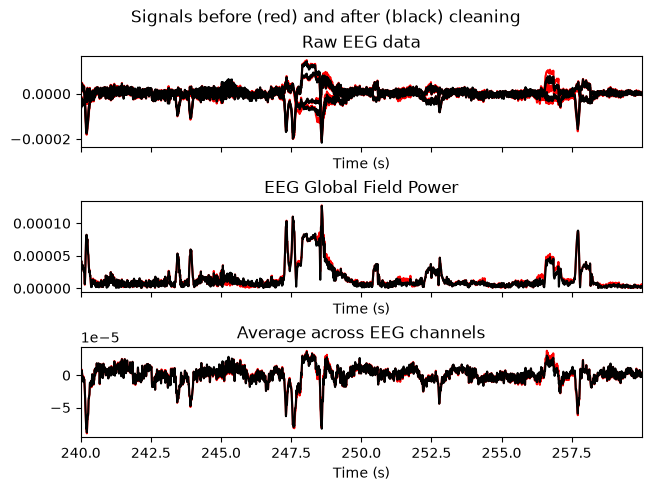

In [161]:
proposed_eog_components = [
    1,
]

overlay_figure = ica.plot_overlay(
    raw_preprocessed,

    # Temporarily reconstruct the signals without these components
    exclude=proposed_eog_components,

    # Inspect the frontal channels most affected by eye movements
    picks=[
        "FP1",
        "FP2",
        "F3",
        "F4",
    ],

    start=240.0,
    stop=260.0,
    show=True,
)

overlay_figure.savefig(
    ica_figures_folder
    / "ocular_correction_overlay.png",
    dpi=300,
    bbox_inches="tight",
)


## Create new copy of raw_preprocessed without contributions of ICA000, ICA005

- Cut continuous recording into stimulus-locked EEG epochs (200ms before, 1500 ms after test-presentation)
- baselien-corrected every channel using its mean voltage from (-200ms, 0ms)
- assigned each epoch its label (correct_old or correct_new)


In [162]:
# Components confirmed as ocular artifacts
ica.exclude = [
    1,
]

# Preserve the data before ICA correction
raw_ica_clean = raw_preprocessed.copy()

# Reconstruct the scalp EEG without components 0 and 5
#(converts electrode signals into ica components, sets components 0 and 5 to zero, reconstructs electrode signals from remaining components)
ica.apply(
    raw_ica_clean
)

print("Removed ICA components:", ica.exclude)
print(raw_ica_clean)






# Keep the 32 scalp channels and four EOG channels for artifact inspection
epoch_channels = (
    scalp_eeg_channels
    + eog_channels
)

epochs = mne.Epochs(
    raw_ica_clean,

    # Event locations updated for the 250-Hz sampling rate
    events=events_resampled,

    # Maps event numbers back to their class names
    event_id=event_id,

    # Begin 200 ms before item presentation
    tmin=-0.2,

    # End 1500 ms after item presentation
    tmax=1.5,

    # Subtract the mean voltage from the prestimulus period (-200 ms before to test-simulus)
    baseline=(-0.2, 0.0),

    picks=epoch_channels,

    preload=True,
    reject_by_annotation=True,

    # Do not reject trials automatically yet
    reject=None,
)

print(epochs)
print("Epoch data shape:", epochs.get_data().shape)
print("Correct-old epochs:", len(epochs["correct_old"]))
print("Correct-new epochs:", len(epochs["correct_new"]))

Applying ICA to Raw instance
    Transforming to ICA space (7 components)
    Zeroing out 1 ICA component
    Projecting back using 32 PCA components
Removed ICA components: [1]
<RawCNT | 3103.cnt, 38 x 749750 (2999.0 s), ~217.4 MiB, data loaded>
Not setting metadata
259 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 259 events and 426 original time points ...
0 bad epochs dropped
<Epochs | 259 events (all good), -0.2 – 1.5 s (baseline -0.2 – 0 s), ~30.3 MiB, data loaded,
 'correct_old': 138
 'correct_new': 121>
Epoch data shape: (259, 36, 426)
Correct-old epochs: 138
Correct-new epochs: 121


## Check for remaining artifacts

Now, we are looking to see if artifacts remain in our data, so we look at Peak-to-Peak voltage in all of our epochs, and classifying what percentage fall under various ptp values.

Examine if artifacts remain in the data by looking at peak-to-peak voltage in all epochs.

Classify what percentage of measurements fall under various Vptp values:

As shown, all voltage values fall under 601.4 uV, so the extreme artifacts were indeed removed.


In [163]:
# Extract only the 32 scalp-EEG channels
# Shape: trials × channels × time samples
eeg_epoch_data_microvolts = (
    epochs.get_data(
        picks=scalp_eeg_channels
    )
    * 1e6
)

# Calculate the peak-to-peak voltage for every channel in every trial
# Shape: trials × channels
channel_peak_to_peak = np.ptp(
    eeg_epoch_data_microvolts,
    axis=2,
)

# For each trial, find its largest channel peak-to-peak voltage
# Shape: trials
epoch_max_peak_to_peak = np.max(
    channel_peak_to_peak,
    axis=1,
)

print(
    "Epoch maximum peak-to-peak percentiles:"
)

for percentile in [
    50,
    75,
    90,
    95,
    97.5,
    99,
    100,
]:
    value = np.percentile(
        epoch_max_peak_to_peak,
        percentile,
    )

    print(
        f"{percentile:>4}%: {value:.1f} µV"
    )

Epoch maximum peak-to-peak percentiles:
  50%: 152.9 µV
  75%: 189.1 µV
  90%: 217.4 µV
  95%: 253.4 µV
97.5%: 292.8 µV
  99%: 392.8 µV
 100%: 985.6 µV


## Epoch Analysis

- For each epoch and each scalp-EEG channel, calculate peak-to-peak voltage (maximium-minimum voltage over the epoch)
- For each epoch, retain the largest peak-to-peak value across its scalp channels
- Identify epochs with the largest peak-to-peak values as candidates for artifact inspection
- Plot the distribution of each epoch's maximum scalp-channel peak-to-peak voltage to inform artifact rejection threshold.


In [164]:
label_from_number = {
    number: label
    for label, number in event_id.items()
}

worst_epoch_indices = np.argsort(
    epoch_max_peak_to_peak
)[::-1][:10]

print("\nTen largest-amplitude epochs:")

for epoch_index in worst_epoch_indices:

    worst_channel_index = np.argmax(
        channel_peak_to_peak[epoch_index]
    )

    worst_channel = (
        scalp_eeg_channels[
            worst_channel_index
        ]
    )

    event_number = epochs.events[
        epoch_index,
        2,
    ]

    print(
        f"Epoch {epoch_index:3d}:",
        f"{epoch_max_peak_to_peak[epoch_index]:8.1f} µV,",
        f"channel={worst_channel},",
        f"label={label_from_number[event_number]}",
    )


Ten largest-amplitude epochs:
Epoch 169:    985.6 µV, channel=FP1, label=correct_old
Epoch   8:    470.3 µV, channel=O2, label=correct_new
Epoch  13:    466.5 µV, channel=FP2, label=correct_new
Epoch 235:    339.5 µV, channel=OZ, label=correct_new
Epoch 160:    334.9 µV, channel=FP2, label=correct_new
Epoch  34:    297.4 µV, channel=FP2, label=correct_old
Epoch  73:    295.2 µV, channel=O2, label=correct_old
Epoch 220:    289.9 µV, channel=PO1, label=correct_old
Epoch 245:    283.1 µV, channel=PO1, label=correct_new
Epoch   2:    278.6 µV, channel=P3, label=correct_old


## Distribution Plot (For Bad Epoch Analysis Analysis)

Plot the distribution of maximum Vptp to see how many epochs fall under certain maximum Vptp values (to get a better sense)


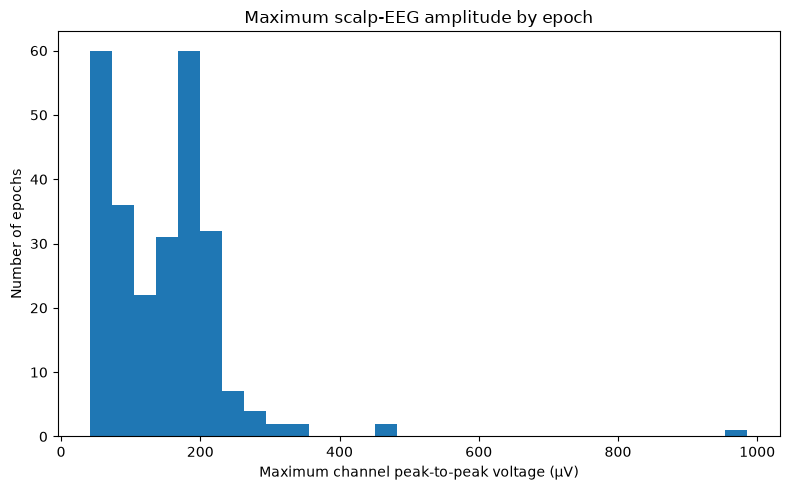

In [165]:
import matplotlib.pyplot as plt

epoch_qc_folder = (
    project_folder
    / "results"
    / "figures"
    / "epoch_qc"
    / participant_id
)

epoch_qc_folder.mkdir(
    parents=True,
    exist_ok=True,
)

figure, axis = plt.subplots(
    figsize=(8, 5)
)

axis.hist(
    epoch_max_peak_to_peak,
    bins=30,
)

axis.set(
    title="Maximum scalp-EEG amplitude by epoch",
    xlabel="Maximum channel peak-to-peak voltage (µV)",
    ylabel="Number of epochs",
)

figure.tight_layout()

figure.savefig(
    epoch_qc_folder
    / "epoch_peak_to_peak_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Artifact-Rejection Threshold Candidates

- look at how many epochs certain thresholds would reject

**Decision: Reject epochs over 200 uV**


In [166]:
"""
epoch_labels = np.array([
    label_from_number[event_number]
    for event_number in epochs.events[:, 2]
])

possible_thresholds = [
    150,
    175,
    200,
    225,
    250,
    300,
    400,
]

print(
    "Threshold | Rejected | Old rejected | New rejected"
)

for threshold in possible_thresholds:

    rejected = (
        epoch_max_peak_to_peak
        > threshold
    )

    rejected_labels = Counter(
        epoch_labels[rejected]
    )

    print(
        f"{threshold:>4} µV   |",
        f"{rejected.sum():>8} |",
        f"{rejected_labels['correct_old']:>12} |",
        f"{rejected_labels['correct_new']:>12}",
    )

epochs[
    worst_epoch_indices
].plot(
    picks=scalp_eeg_channels,
    n_epochs=10,
    n_channels=len(scalp_eeg_channels),
    scalings={
        "eeg": 200e-6,
    },
    block=True,
)
"""

'\nepoch_labels = np.array([\n    label_from_number[event_number]\n    for event_number in epochs.events[:, 2]\n])\n\npossible_thresholds = [\n    150,\n    175,\n    200,\n    225,\n    250,\n    300,\n    400,\n]\n\nprint(\n    "Threshold | Rejected | Old rejected | New rejected"\n)\n\nfor threshold in possible_thresholds:\n\n    rejected = (\n        epoch_max_peak_to_peak\n        > threshold\n    )\n\n    rejected_labels = Counter(\n        epoch_labels[rejected]\n    )\n\n    print(\n        f"{threshold:>4} µV   |",\n        f"{rejected.sum():>8} |",\n        f"{rejected_labels[\'correct_old\']:>12} |",\n        f"{rejected_labels[\'correct_new\']:>12}",\n    )\n\nepochs[\n    worst_epoch_indices\n].plot(\n    picks=scalp_eeg_channels,\n    n_epochs=10,\n    n_channels=len(scalp_eeg_channels),\n    scalings={\n        "eeg": 200e-6,\n    },\n    block=True,\n)\n'

## Reject the epochs with peak-to-peak voltage over 200 uV.


In [167]:
artifact_threshold_microvolts = 225

# Create a copy so the original epochs remain available
epochs_clean = epochs.copy()

epochs_clean.drop_bad(
    reject={
        # MNE expects volts:
        # 200 µV = 200 × 10^-6 V
        "eeg": (
            artifact_threshold_microvolts
            * 1e-6
        ),
    }
)

print(
    "Epochs before rejection:",
    len(epochs),
)

print(
    "Epochs after rejection:",
    len(epochs_clean),
)

print(
    "Epochs rejected:",
    len(epochs) - len(epochs_clean),
)

print(
    "Remaining correct-old:",
    len(epochs_clean["correct_old"]),
)

print(
    "Remaining correct-new:",
    len(epochs_clean["correct_new"]),
)

    Rejecting  epoch based on EEG : ['F8', 'FT7', 'FC3', 'FC4', 'FT8', 'T3', 'C3', 'C4', 'T4', 'TP7', 'CP3', 'CP4', 'TP8', 'T5', 'P3', 'PZ', 'P4', 'T6', 'O1', 'OZ', 'O2', 'PO1', 'PO2']
    Rejecting  epoch based on EEG : ['T5', 'OZ', 'O2', 'PO2']
    Rejecting  epoch based on EEG : ['F7', 'F3', 'FZ', 'F4', 'F8', 'FT7', 'FC3', 'FCZ', 'FC4', 'FT8', 'T3', 'C3', 'CZ', 'C4', 'T4', 'TP7', 'CP3', 'CPZ', 'CP4', 'TP8', 'T5', 'P3', 'PZ', 'P4', 'T6', 'O1', 'OZ', 'O2', 'PO1', 'PO2']
    Rejecting  epoch based on EEG : ['FC3', 'T3', 'C3', 'TP7', 'CP3', 'CP4', 'T5', 'P3', 'P4', 'T6', 'O1', 'OZ', 'O2', 'PO1', 'PO2']
    Rejecting  epoch based on EEG : ['FP2', 'FT7', 'FC3', 'FC4', 'FT8', 'T3', 'C3', 'C4', 'T4', 'TP7', 'CP3', 'CP4', 'TP8', 'T5', 'P3', 'PZ', 'P4', 'T6', 'O1', 'OZ', 'O2', 'PO1', 'PO2']
    Rejecting  epoch based on EEG : ['T5', 'O2']
    Rejecting  epoch based on EEG : ['FP2']
    Rejecting  epoch based on EEG : ['FT7', 'T3', 'TP7', 'CP3', 'T5', 'P3', 'T6']
    Rejecting  epoch based on 

## Save cleaned epochs and ICA solution for this participant


In [168]:
processed_data_folder = (
    project_folder
    / "data"
    / "processed"
)

processed_data_folder.mkdir(
    parents=True,
    exist_ok=True,
)

epochs_file = (
    processed_data_folder
    / f"{participant_id}_clean-epo.fif"
)

ica_file = (
    processed_data_folder
    / f"{participant_id}-ica.fif"
)

epochs_clean.save(
    epochs_file,
    overwrite=True,
)

ica.save(
    ica_file,
    overwrite=True,
)

print("Saved epochs:", epochs_file)
print("Saved ICA:", ica_file)

Overwriting existing file.
Overwriting existing file.
Overwriting existing file.
Overwriting existing file.
Writing ICA solution to /Users/reedsussman/Desktop/thapar_lab/data/processed/3103-ica.fif...
Overwriting existing file.
Saved epochs: /Users/reedsussman/Desktop/thapar_lab/data/processed/3103_clean-epo.fif
Saved ICA: /Users/reedsussman/Desktop/thapar_lab/data/processed/3103-ica.fif
